# Combined Autoplius SOM model

This notebook intentionally uses the separate `cleaning_autoplius(1).ipynb` output instead of repeating the raw-data cleaning code here.

Pipeline:
1. Load `autoplius_cars_cleaned.csv` from the cleaning notebook.
2. Refit the selected price-regression model from `auto_price_reg(1).ipynb`.
3. Optionally attach the inspection-failure risk table produced from the separate inspection CSV.
4. Train the SOM using the original SOM notebook flow, with SOM-style engineered features recreated from the cleaned columns that are available.


In [2]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from minisom import MiniSom

import statsmodels.formula.api as smf

np.random.seed(42)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["font.size"] = 11


## 1. Paths and parameters

In [28]:
CLEANED_AUTOPLIUS_PATH = Path("autoplius_cars_cleaned.csv")

INSPECTION_RISK_TABLE_CANDIDATES = [
    Path("../models/high_risk_model_mileage_pairs.csv"),
    Path("models/high_risk_model_mileage_pairs.csv"),
]

ENRICHED_OUTPUT_PATH = Path("autoplius_cars_som_enriched.csv")
SOM_RESULTS_OUTPUT_PATH = Path("som_suspicious_ads.csv")

SOM_PARAMS = {
    "map_size": 20,
    "learning_rate": 0.1,
    "sigma": None,
    "iterations": None,
    "neighborhood_function": "gaussian",
    "topology": "rectangular",
}

PRICE_CEILING_EUR = 40000

FRAUD_PARAMS = {
    "suspect_pct": 5,
    "top_k": 30,
}


## 2. Load cleaned Autoplius data


In [29]:
if not CLEANED_AUTOPLIUS_PATH.exists():
    raise FileNotFoundError(
        f"Missing {CLEANED_AUTOPLIUS_PATH}. Run cleaning_autoplius.ipynb first."
    )

df = pd.read_csv(CLEANED_AUTOPLIUS_PATH)
print(f"Loaded cleaned data: {CLEANED_AUTOPLIUS_PATH} ({len(df):,} rows)")
df.head()


Loaded cleaned data: autoplius_cars_cleaned.csv (14,504 rows)


,first_registration_year,mileage_km,engine_cc,horsepower_ag,power_kw,is_electric,model,price_eur,location,first_reg_abroad,country_grp,manufacturer_grp,ti_months,has_defects,fuel_type
0,2018.0,151000.0,1969.0,250.0,184.0,False,Volvo XC60,23500.0,"Vilnius, Lietuva",False,Lithuania,Volvo,10.052562,False,Benzinas
1,1987.0,312000.0,1760.0,90.0,66.0,False,Audi 80,1550.0,"Vilnius, Lietuva",True,Germany,Audi,26.018397,False,Benzinas
2,NaN,312321.0,1896.0,116.0,85.0,False,Volkswagen Sharan,1000.0,"Vilnius, Lietuva",False,Lithuania,Volkswagen,7.030223,False,Dyzelinas
3,2008.0,350000.0,1896.0,105.0,77.0,False,Volkswagen Passat,1400.0,"Vilnius, Lietuva",False,Lithuania,Volkswagen,17.017083,False,Dyzelinas
4,2010.0,352150.0,1968.0,140.0,103.0,False,Skoda Octavia,3650.0,"Vilnius, Lietuva",False,Lithuania,Skoda,11.070959,False,Dyzelinas


## 2b. Apply price ceiling filter

Cars listed above `PRICE_CEILING_EUR` are removed before any modelling.
Luxury/collector vehicles operate in a fundamentally different sub-market:
their price dynamics are driven by rarity and brand prestige rather than the age/mileage/engine signals the regression and SOM rely on.

In [30]:
if PRICE_CEILING_EUR is not None:
    before = len(df)
    df = df[df["price_eur"] <= PRICE_CEILING_EUR].copy()
    removed = before - len(df)
    print(
        f"Price ceiling filter: removed {removed:,} listings "
        f"(price_eur > {PRICE_CEILING_EUR:,} EUR) "
        f"— {removed / before * 100:.1f}% of raw data"
    )
else:
    print("Price ceiling filter disabled — all price ranges included.")

print(f"Remaining rows: {len(df):,}")

# Quick sanity check: price distribution after filtering
print("\nPrice distribution after ceiling filter:")
print(df["price_eur"].describe().round(0))


Price ceiling filter: removed 628 listings (price_eur > 40,000 EUR) — 4.3% of raw data
Remaining rows: 13,876

Price distribution after ceiling filter:
count    13876.0
mean     10473.0
std       8058.0
min        245.0
25%       4500.0
50%       8150.0
75%      14390.0
max      40000.0
Name: price_eur, dtype: float64


## 3. Add selected price-regression model output

In [31]:
df = df.copy()
df["age"] = 2026 - df["first_registration_year"]

price_required = [
    "price_eur", "age", "mileage_km", "engine_cc", "horsepower_ag",
    "ti_months", "country_grp", "manufacturer_grp", "has_defects",
]

df_model = df.replace([np.inf, -np.inf], np.nan).dropna(subset=price_required).copy()
df_model = df_model[df_model["price_eur"] > 0].copy()

df_shuffled = df_model.sample(frac=1, random_state=42)
train_end = int(0.7 * len(df_shuffled))
val_end = int(0.85 * len(df_shuffled))

dt_train = df_shuffled.iloc[:train_end].copy()
dt_val = df_shuffled.iloc[train_end:val_end].copy()
dt_test = df_shuffled.iloc[val_end:].copy()

dt_trainval = pd.concat([dt_train, dt_val], axis=0)

price_formula = (
    "np.log(price_eur) ~ age + I(age**2) + mileage_km + I(mileage_km**2) "
    "+ age:mileage_km + engine_cc + horsepower_ag + ti_months "
    "+ C(has_defects) + C(country_grp) + C(manufacturer_grp)"
)

m13_final = smf.ols(price_formula, data=dt_trainval).fit(cov_type="HC1")
smear = np.mean(np.exp(m13_final.resid))

df_model["pred_price_eur"] = np.exp(m13_final.predict(df_model)) * smear
df_model["price_delta_eur"] = df_model["price_eur"] - df_model["pred_price_eur"]
df_model["price_ratio"] = df_model["price_eur"] / df_model["pred_price_eur"]
df_model["abs_price_pct_error"] = (
    (df_model["price_eur"] - df_model["pred_price_eur"]).abs()
    / df_model["price_eur"]
)

log_pred_test = m13_final.predict(dt_test)
pred_test = np.exp(log_pred_test) * smear
actual_test = dt_test["price_eur"]

rmse_test = np.sqrt(np.mean((actual_test - pred_test) ** 2))
mae_test = np.mean(np.abs(actual_test - pred_test))
mape_test = np.mean(np.abs((actual_test - pred_test) / actual_test)) * 100

print("Price model test metrics")
print(f"RMSE: {rmse_test:.2f}")
print(f"MAE:  {mae_test:.2f}")
print(f"MAPE: {mape_test:.2f}%")

df_model[["price_eur", "pred_price_eur", "price_ratio", "abs_price_pct_error"]].head()


Price model test metrics
RMSE: 4947.98
MAE:  2934.05
MAPE: 33.73%


,price_eur,pred_price_eur,price_ratio,abs_price_pct_error
0,23500.0,16228.871199,1.448037,0.309410
1,1550.0,1242.309332,1.247676,0.198510
3,1400.0,3220.061663,0.434774,1.300044
4,3650.0,3638.660836,1.003116,0.003107
5,4400.0,5428.657175,0.810514,0.233786


## 4. Add inspection-failure risk from the result table only

The inspection model was trained on a different dataset, so this section only loads its exported table and merges the predicted failure probability into the Autoplius listing rows.

Expected table columns:

- `vehicle_label`
- `tp_rida_km`
- `predicted_failure_probability`
- `model_row_count`

In [32]:
def normalize_vehicle_label(value):
    if pd.isna(value):
        return "UNKNOWN"
    text = str(value).strip().upper()
    text = re.sub(r"\s+", " ", text)
    return text if text else "UNKNOWN"


def find_inspection_risk_table(candidates):
    for candidate in candidates:
        if candidate.exists():
            return candidate
    return None


def attach_inspection_risk(df_in, risk_table_candidates=INSPECTION_RISK_TABLE_CANDIDATES):
    df_out = df_in.copy()
    df_out["inspection_fail_probability"] = np.nan
    df_out["inspection_model_row_count"] = 0
    df_out["inspection_risk_source"] = "not_available"

    risk_table_path = find_inspection_risk_table(risk_table_candidates)
    if risk_table_path is None:
        print("Inspection risk table not found. Continuing without inspection-risk signal.")
        df_out["inspection_fail_probability"] = 0.0
        return df_out

    print(f"Loaded inspection risk table: {risk_table_path}")
    risk = pd.read_csv(risk_table_path)
    needed = {
        "vehicle_label",
        "tp_rida_km",
        "predicted_failure_probability",
        "model_row_count",
    }
    missing = needed - set(risk.columns)
    if missing:
        raise ValueError(f"Inspection risk table is missing columns: {missing}")

    risk = risk.copy()
    risk["vehicle_label_norm"] = risk["vehicle_label"].map(normalize_vehicle_label)
    risk["tp_rida_km"] = pd.to_numeric(risk["tp_rida_km"], errors="coerce")
    risk["predicted_failure_probability"] = pd.to_numeric(
        risk["predicted_failure_probability"], errors="coerce"
    )
    risk = risk.dropna(subset=["vehicle_label_norm", "tp_rida_km", "predicted_failure_probability"])

    df_out["vehicle_label_norm"] = df_out["model"].map(normalize_vehicle_label)

    risk_by_model = {
        label: grp.sort_values("tp_rida_km").reset_index(drop=True)
        for label, grp in risk.groupby("vehicle_label_norm")
    }

    probs = []
    counts = []
    sources = []

    for label, mileage in zip(df_out["vehicle_label_norm"], df_out["mileage_km"]):
        grp = risk_by_model.get(label)

        if grp is None or pd.isna(mileage):
            probs.append(np.nan)
            counts.append(0)
            sources.append("no_exact_model")
            continue

        nearest_idx = (grp["tp_rida_km"] - mileage).abs().idxmin()
        row = grp.loc[nearest_idx]

        probs.append(float(row["predicted_failure_probability"]))
        counts.append(int(row["model_row_count"]))
        sources.append("exact_model_nearest_mileage_bucket")

    df_out["inspection_fail_probability"] = probs
    df_out["inspection_model_row_count"] = counts
    df_out["inspection_risk_source"] = sources

    median_prob = risk["predicted_failure_probability"].median()
    df_out["inspection_fail_probability"] = df_out["inspection_fail_probability"].fillna(median_prob)

    return df_out


df_model = attach_inspection_risk(df_model)
df_model[[
    "model", "mileage_km", "inspection_fail_probability",
    "inspection_model_row_count", "inspection_risk_source"
]].head()


Inspection risk table not found. Continuing without inspection-risk signal.


,model,mileage_km,inspection_fail_probability,inspection_model_row_count,inspection_risk_source
0,Volvo XC60,151000.0,0.0,0,not_available
1,Audi 80,312000.0,0.0,0,not_available
3,Volkswagen Passat,350000.0,0.0,0,not_available
4,Skoda Octavia,352150.0,0.0,0,not_available
5,Subaru Forester,283000.0,0.0,0,not_available


## 5. Prepare SOM-style engineered features


In [33]:
df_model = df_model.copy()

df_model["engine_hp"] = df_model["horsepower_ag"]
df_model["car_age_years"] = df_model["age"]
df_model["months_until_insp"] = df_model["ti_months"]

df_model["price_per_hp"] = df_model["price_eur"] / df_model["engine_hp"].replace(0, np.nan)
df_model["km_per_year"] = df_model["mileage_km"] / df_model["car_age_years"].replace(0, np.nan)
df_model["price_per_km"] = df_model["price_eur"] / df_model["mileage_km"].replace(0, np.nan)

df_model["price_to_model"] = df_model.groupby("model")["price_eur"].transform(
    lambda x: (x - x.mean()) / (x.std() + 1e-9)
)

df_model["price_to_manufacturer"] = df_model.groupby("manufacturer_grp")["price_eur"].transform(
    lambda x: (x - x.mean()) / (x.std() + 1e-9)
)

age_bins = pd.cut(
    df_model["car_age_years"].fillna(0),
    bins=[0, 3, 7, 12, 20, 100],
    labels=False,
    include_lowest=True,
)
df_model["km_to_age_group"] = df_model.groupby(age_bins)["mileage_km"].transform(
    lambda x: (x - x.mean()) / (x.std() + 1e-9)
)

SOM_FEATURES = [
    "price_eur",
    "mileage_km",
    "engine_cc",
    "car_age_years",
    "km_per_year",
    "price_per_km",
    "price_to_model",
    "price_to_manufacturer",
    "has_defects",
    "months_until_insp",
    "pred_price_eur",
    "price_delta_eur",
    "price_ratio",
    "abs_price_pct_error",
    "inspection_fail_probability",
    "inspection_model_row_count",
    "is_electric",
    "first_reg_abroad",
]


def prep_X(df_in):
    X = df_in[SOM_FEATURES].copy().replace([np.inf, -np.inf], np.nan)
    for col in X.columns:
        if X[col].dtype == bool:
            X[col] = X[col].astype(int)
        X[col] = pd.to_numeric(X[col], errors="coerce")
        X[col] = X[col].fillna(X[col].median())
    return X.values


X_all = prep_X(df_model)
df_train, df_test, X_train_raw, X_test_raw = train_test_split(
    df_model.reset_index(drop=True),
    X_all,
    test_size=0.2,
    random_state=42,
)
df_train = df_train.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

print(f"Train: {len(X_train):,} ads")
print(f"Test:  {len(X_test):,} ads")
print(pd.DataFrame(X_train_raw, columns=SOM_FEATURES).describe().round(1).to_string())


Train: 8,363 ads
Test:  2,091 ads
       price_eur  mileage_km  engine_cc  car_age_years  km_per_year  price_per_km  price_to_model  price_to_manufacturer  has_defects  months_until_insp  pred_price_eur  price_delta_eur  price_ratio  abs_price_pct_error  inspection_fail_probability  inspection_model_row_count  is_electric  first_reg_abroad
count     8363.0      8363.0     8363.0         8363.0       8363.0        8363.0          8363.0                 8363.0       8363.0             8363.0          8363.0           8363.0       8363.0               8363.0                       8363.0                      8363.0       8363.0            8363.0
mean     10726.6    225279.0     2065.5           11.8      21494.3           4.6            -0.0                   -0.0          0.0                9.2         11203.3           -476.7          1.0                  0.4                          0.0                         0.0          0.0               0.5
std       8127.8    111252.8      702.1   

## 6. Train SOM

In [34]:
n = X_train.shape[0]
recommended_neurons = 5 * np.sqrt(n)

map_size = SOM_PARAMS["map_size"]
sigma = SOM_PARAMS["sigma"] if SOM_PARAMS["sigma"] is not None else map_size * 0.5
iterations = (
    SOM_PARAMS["iterations"]
    if SOM_PARAMS["iterations"] is not None
    else int(recommended_neurons * 500)
)

print(f"Recommended SOM parameters for {n:,} samples:")
print(f"  Map size:      {map_size}x{map_size} ({map_size**2} neurons)")
print(f"  Iterations:    {iterations:,}")
print(f"  Learning rate: {SOM_PARAMS['learning_rate']}")
print(f"  Sigma:         {sigma}")

som = MiniSom(
    x=map_size,
    y=map_size,
    input_len=X_train.shape[1],
    sigma=sigma,
    learning_rate=SOM_PARAMS["learning_rate"],
    neighborhood_function=SOM_PARAMS["neighborhood_function"],
    topology=SOM_PARAMS["topology"],
    random_seed=42,
)

som.random_weights_init(X_train)
som.train_batch(X_train, num_iteration=iterations, verbose=True)

Recommended SOM parameters for 8,363 samples:
  Map size:      20x20 (400 neurons)
  Iterations:    228,623
  Learning rate: 0.1
  Sigma:         10.0
 [ 228623 / 228623 ] 100% - 0:00:00 left 
 quantization error: 0.17917797003749394


## 7. Extract SOM anomaly score

In [35]:
def extract_som_features(som, X, map_size):
    clusters, dists = [], []
    weights = som.get_weights()

    for x in X:
        bmu = som.winner(x)
        bmu_w = weights[bmu[0], bmu[1]]
        clusters.append(bmu[0] * 100000 + bmu[1])
        dists.append(np.linalg.norm(x - bmu_w))

    return np.array(clusters, dtype=float), np.array(dists)


som_cluster_train, som_dist_train = extract_som_features(som, X_train, map_size)
som_cluster_test, som_dist_test = extract_som_features(som, X_test, map_size)

print("SOM features ready.")
print(
    f"  Clusters: {len(np.unique(som_cluster_train))} unique | "
    f"distance range [{som_dist_train.min():.2f}, {som_dist_train.max():.2f}]"
)

threshold_dist = np.percentile(som_dist_train, 100 - FRAUD_PARAMS["suspect_pct"])
suspect_train = som_dist_train > threshold_dist
suspect_test = som_dist_test > threshold_dist

df_train["som_cluster"] = som_cluster_train.astype(int)
df_train["som_distance"] = som_dist_train
df_train["som_suspect"] = suspect_train

df_test["som_cluster"] = som_cluster_test.astype(int)
df_test["som_distance"] = som_dist_test
df_test["som_suspect"] = suspect_test

print(f"SOM distance threshold: {threshold_dist:.4f}")
print(f"Suspect share in test: {df_test['som_suspect'].mean() * 100:.2f}%")


SOM features ready.
  Clusters: 264 unique | distance range [0.03, 1.47]
SOM distance threshold: 0.4665
Suspect share in test: 6.36%


## 8. Visualize SOM and anomaly threshold

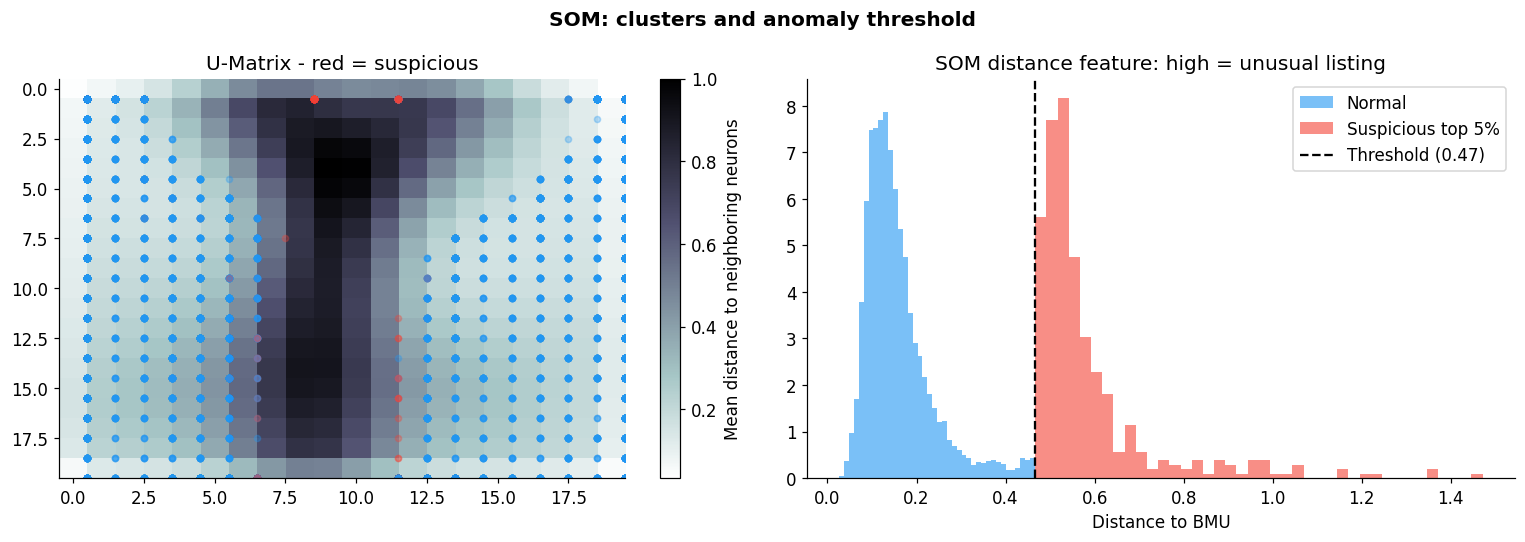

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("SOM: clusters and anomaly threshold", fontweight="bold")

ax = axes[0]
im = ax.imshow(som.distance_map().T, cmap="bone_r", aspect="auto")
plt.colorbar(im, ax=ax, label="Mean distance to neighboring neurons")

for x_pt, is_suspect in zip(X_train, suspect_train):
    bmu = som.winner(x_pt)
    ax.plot(
        bmu[0] + 0.5,
        bmu[1] + 0.5,
        "o",
        color="#F44336" if is_suspect else "#2196F3",
        alpha=0.3,
        ms=4,
    )

ax.set_title("U-Matrix - red = suspicious")

ax2 = axes[1]
ax2.hist(
    som_dist_train[~suspect_train],
    bins=40,
    alpha=0.6,
    color="#2196F3",
    label="Normal",
    density=True,
)
ax2.hist(
    som_dist_train[suspect_train],
    bins=40,
    alpha=0.6,
    color="#F44336",
    label=f"Suspicious top {FRAUD_PARAMS['suspect_pct']}%",
    density=True,
)
ax2.axvline(
    threshold_dist,
    color="black",
    lw=1.5,
    linestyle="--",
    label=f"Threshold ({threshold_dist:.2f})",
)
ax2.set_title("SOM distance feature: high = unusual listing")
ax2.set_xlabel("Distance to BMU")
ax2.legend()

plt.tight_layout()
plt.show()


## 9. Final suspicious listing table

In [37]:
id_cols = []
for possible_id in ["ad_id"]:
    if possible_id in df_test.columns:
        id_cols.append(possible_id)

result_cols = id_cols + [
    "model",
    "price_eur",
    "pred_price_eur",
    "price_ratio",
    "abs_price_pct_error",
    "mileage_km",
    "car_age_years",
    "km_per_year",
    "price_to_model",
    "has_defects",
    "inspection_fail_probability",
    "inspection_model_row_count",
    "inspection_risk_source",
    "som_cluster",
    "som_distance",
    "som_suspect",
]

results = df_test[result_cols].copy().reset_index(drop=True)
results["som_distance"] = results["som_distance"].round(4)
results["price_ratio"] = results["price_ratio"].round(3)
results["abs_price_pct_error"] = results["abs_price_pct_error"].round(3)
results["inspection_fail_probability"] = results["inspection_fail_probability"].round(4)

top_k = FRAUD_PARAMS["top_k"]
top_results = results.nlargest(top_k, "som_distance")

print(f"Top-{top_k} according to SOM distance (test):")
display(top_results)

results.to_csv(SOM_RESULTS_OUTPUT_PATH, index=False)
print(f"Saved SOM results to: {SOM_RESULTS_OUTPUT_PATH}")


Top-30 according to SOM distance (test):


,model,price_eur,pred_price_eur,price_ratio,abs_price_pct_error,mileage_km,car_age_years,km_per_year,price_to_model,has_defects,inspection_fail_probability,inspection_model_row_count,inspection_risk_source,som_cluster,som_distance,som_suspect
955,Dodge Challenger,35000.0,146123.350115,0.240,3.175,27600.0,4.0,6900.000000,1.423800,False,0.0,0,not_available,1100019,1.3429,True
54,Mercedes-Benz Sprinter,19450.0,50722.433895,0.383,1.608,270000.0,1.0,270000.000000,0.992054,False,0.0,0,not_available,19,1.1247,True
1696,BMW 525,3200.0,1902.480392,1.682,0.405,3000000.0,19.0,157894.736842,-0.879613,False,0.0,0,not_available,300004,0.9822,True
378,BMW X2,30990.0,26225.557077,1.182,0.154,7556.0,1.0,7556.000000,1.054261,True,0.0,0,not_available,1100000,0.9135,True
654,Dodge Durango,18800.0,53433.782670,0.352,1.842,82400.0,4.0,20600.000000,0.084795,True,0.0,0,not_available,1100000,0.8931,True
1213,Ford Mustang,18900.0,37605.891835,0.503,0.990,74384.0,4.0,18596.000000,-0.502027,True,0.0,0,not_available,800000,0.8423,True
634,Lexus LX 570,19700.0,13439.793319,1.466,0.318,200000.0,14.0,14285.714286,NaN,True,0.0,0,not_available,800000,0.8414,True
519,BMW M4,22500.0,48301.020047,0.466,1.147,23.0,0.0,NaN,-1.408535,True,0.0,0,not_available,800000,0.8110,True
1660,BMW 540,18000.0,47921.008725,0.376,1.662,10000.0,0.0,NaN,-1.040251,True,0.0,0,not_available,800000,0.7413,True
1483,BMW 120,13000.0,14462.588964,0.899,0.113,170000.0,5.0,34000.000000,3.636355,True,0.0,0,not_available,1100000,0.7362,True


Saved SOM results to: som_suspicious_ads.csv


## 10. Save enriched full dataset

In [38]:
df_combined = pd.concat([df_train, df_test], axis=0).reset_index(drop=True)
df_combined.to_csv(ENRICHED_OUTPUT_PATH, index=False)

print(f"Saved enriched data to: {ENRICHED_OUTPUT_PATH}")
print(f"Rows: {len(df_combined):,}")
print(f"Columns: {len(df_combined.columns):,}")

Saved enriched data to: autoplius_cars_som_enriched.csv
Rows: 10,454
Columns: 35
